
1003_TRIAL_1_LABELED_DATA.xlsx
Rows: 61,628
Start / end: 0.22 / 614.45 seconds
Duration: 614.23 seconds
Estimated sampling rate: 100.33 Hz

Columns:
['time', 'seconds_elapsed', 'rotationRateX', 'rotationRateY', 'rotationRateZ', 'accelerationX', 'accelerationY', 'accelerationZ', 'label', 'session_id']

Missing values:
time               0
seconds_elapsed    0
rotationRateX      0
rotationRateY      0
rotationRateZ      0
accelerationX      0
accelerationY      0
accelerationZ      0
label              0
session_id         0
dtype: int64

Timestamp checks:
Repeated timestamps: 0
Backward time steps: 0
Largest time gap: 0.0100 seconds

Label summary:
               Rows  Approx. seconds  Percent
label                                        
not-swimming  23594           235.16     38.3
breaststroke   8998            89.68     14.6
backstroke     7411            73.87     12.0
transition     7279            72.55     11.8
butterfly      6584            65.62     10.7
freestyle      6312  

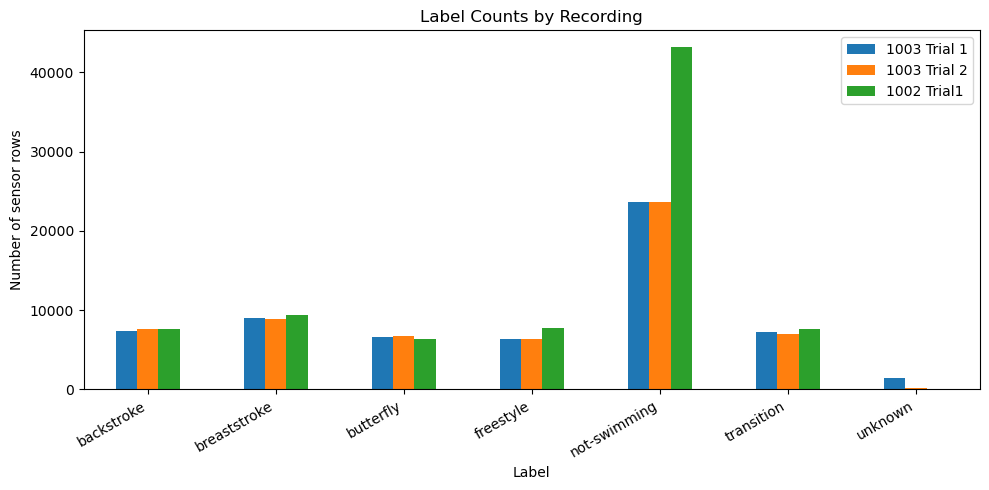

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

files = [
    "1003_TRIAL_1_LABELED_DATA.xlsx",
    "1003_TRIAL_2_LABELED_DATA.xlsx",
    "1002_LABELED_DATA.xlsx"
]

recordings = []

for session, file in enumerate(files, start=1):
    df = pd.read_excel(file)

    # Standardize column names and labels
    df.columns = df.columns.str.strip()
    df = df.rename(columns={"label (all lowercase)": "label"})
    df["label"] = df["label"].astype("string").str.strip().str.lower()

    df["session_id"] = session
    recordings.append(df)

    time = df["seconds_elapsed"]
    dt = time.diff().median()

    print(f"\n{'=' * 50}")
    print(file)
    print(f"Rows: {len(df):,}")
    print(f"Start / end: {time.iloc[0]:.2f} / {time.iloc[-1]:.2f} seconds")
    print(f"Duration: {time.iloc[-1] - time.iloc[0]:.2f} seconds")
    print(f"Estimated sampling rate: {1 / dt:.2f} Hz")

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nTimestamp checks:")
    print("Repeated timestamps:", time.duplicated().sum())
    print("Backward time steps:", (time.diff() < 0).sum())
    print(f"Largest time gap: {time.diff().max():.4f} seconds")

    # Approximate duration assumes regular sampling
    counts = df["label"].value_counts(dropna=False)
    summary = pd.DataFrame({
        "Rows": counts,
        "Approx. seconds": (counts * dt).round(2),
        "Percent": (counts / len(df) * 100).round(1)
    })

    print("\nLabel summary:")
    print(summary)

# Combine while preserving recording identity
all_data = pd.concat(recordings, ignore_index=True)

# Compare label counts between recordings
label_counts = pd.crosstab(
    all_data["label"],
    all_data["session_id"]
)

label_counts.columns = ["1003 Trial 1", "1003 Trial 2", "1002 Trial1"]

print("\nLABEL COUNTS BY RECORDING")
print(label_counts)

label_counts.plot.bar(figsize=(10, 5))
plt.title("Label Counts by Recording")
plt.xlabel("Label")
plt.ylabel("Number of sensor rows")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import pandas as pd

measurements = [
    "accelerationX", "accelerationY", "accelerationZ",
    "rotationRateX", "rotationRateY", "rotationRateZ"
]

classes = [
    "butterfly", "backstroke", "breaststroke",
    "freestyle", "transition", "not-swimming"
]

window_seconds = 3
step_seconds = 1
features = []

for recording in recordings:
    data = recording.sort_values("seconds_elapsed").copy()
    data["label"] = data["label"].replace({
        "not_swimming": "not-swimming"
    })

    session = data["session_id"].iloc[0]
    time = data["seconds_elapsed"]
    dt = time.diff().median()

    # Create complete windows across this recording
    start = time.iloc[0]

    while start + window_seconds <= time.iloc[-1]:
        end = start + window_seconds

        window = data[
            (time >= start) & (time < end)
        ]

        start += step_seconds

        # Skip incomplete windows or gaps in the recording
        if len(window) < 0.95 * window_seconds / dt:
            continue

        if window["seconds_elapsed"].diff().max() > 2 * dt:
            continue

        # Skip unknown labels and invalid sensor values
        if not window["label"].isin(classes).all():
            continue

        if not np.isfinite(window[measurements].to_numpy()).all():
            continue

        # Require one label to cover at least 75% of the window
        proportions = window["label"].value_counts(normalize=True)

        if proportions.iloc[0] < 0.75:
            continue

        row = {
            "session_id": session,
            "start_seconds": end - window_seconds,
            "end_seconds": end,
            "label": proportions.index[0],
            "label_fraction": proportions.iloc[0]
        }

        # Calculate 24 features
        for measurement in measurements:
            values = window[measurement]

            row[f"{measurement}_mean"] = values.mean()
            row[f"{measurement}_std"] = values.std()
            row[f"{measurement}_min"] = values.min()
            row[f"{measurement}_max"] = values.max()

        features.append(row)

feature_data = pd.DataFrame(features)

if feature_data.empty:
    print("No windows passed the checks.")
else:
    print("Total windows:", len(feature_data))

    print("\nWINDOWS PER CLASS AND SESSION")
    print(
        pd.crosstab(
            feature_data["label"],
            feature_data["session_id"]
        ).reindex(classes, fill_value=0)
    )

    feature_data.to_csv("swimming_window_features.csv", index=False)
    print("\nSaved: swimming_window_features.csv")

Total windows: 1735

WINDOWS PER CLASS AND SESSION
session_id      1    2    3
label                      
butterfly      58   59   54
backstroke     68   71   69
breaststroke   79   79   86
freestyle      55   56   71
transition     39   38   44
not-swimming  205  205  399

Saved: swimming_window_features.csv


TRAINING WINDOWS BY SESSION
session_id
1    504
2    254
3    723
dtype: int64

Total training samples: 1481
Total testing samples: 252
Windows excluded at split boundary: 2

WINDOWS PER CLASS
              Training  Testing
label                          
backstroke         179       29
breaststroke       197       47
butterfly          147       24
freestyle          149       33
not-swimming       708      101
transition         101       18

Test accuracy: 0.9960
Macro-F1: 0.9944

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  backstroke     1.0000    1.0000    1.0000        29
breaststroke     1.0000    1.0000    1.0000        47
   butterfly     1.0000    1.0000    1.0000        24
   freestyle     1.0000    1.0000    1.0000        33
not-swimming     0.9902    1.0000    0.9951       101
  transition     1.0000    0.9444    0.9714        18

    accuracy                         0.9960       252
   macro avg     0.9984    0.9907    0.9944       252


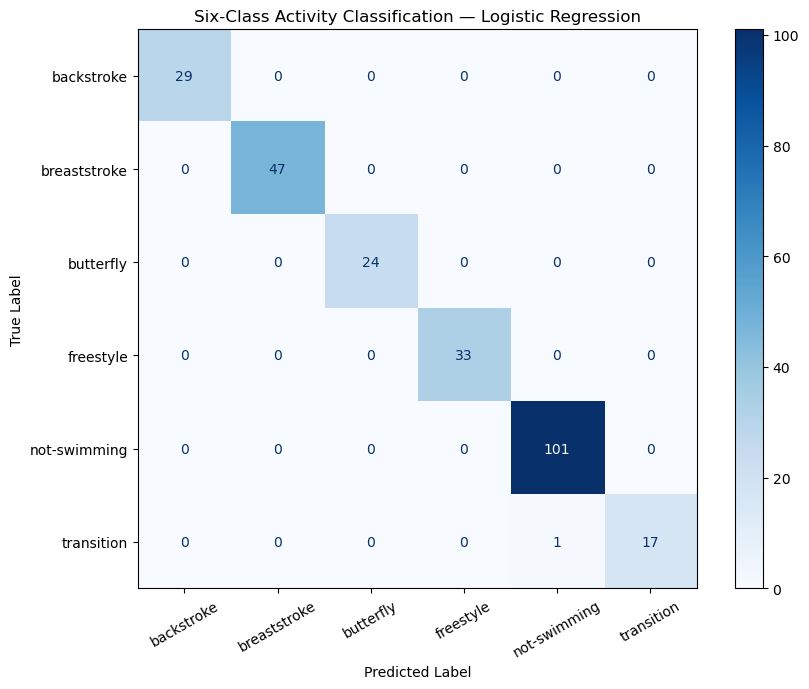

In [17]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)

# 1. Load the window features
df = pd.read_csv("swimming_window_features.csv")

# Select only the 24 statistical features
measurements = [
    "accelerationX", "accelerationY", "accelerationZ",
    "rotationRateX", "rotationRateY", "rotationRateZ"
]

feature_cols = [
    f"{measurement}_{stat}"
    for measurement in measurements
    for stat in ["mean", "std", "min", "max"]
]

classes = [
    "backstroke", "breaststroke", "butterfly",
    "freestyle", "not-swimming", "transition"
]

# 2. Select the three recordings
trial_1 = df[df["session_id"] == 1]
trial_2 = df[df["session_id"] == 2]
data_1002 = df[df["session_id"] == 3]

if trial_1.empty or trial_2.empty or data_1002.empty:
    raise ValueError(
        "One or more sessions are missing. "
        "Rerun the loading and windowing cells with all three files."
    )

# 3. Split Trial 2 at 300 seconds
# Windows crossing the boundary are excluded from both sets
trial_2_train = trial_2[trial_2["end_seconds"] <= 300]
trial_2_test = trial_2[trial_2["start_seconds"] >= 300]

# Train on Trial 1, the first part of Trial 2, and all of 1002
train_df = pd.concat(
    [trial_1, trial_2_train, data_1002],
    ignore_index=True
)

# Test on the second part of Trial 2
test_df = trial_2_test.reset_index(drop=True)

X_train = train_df[feature_cols]
y_train = train_df["label"]

X_test = test_df[feature_cols]
y_test = test_df["label"]

if train_df.empty or test_df.empty:
    raise ValueError("The training or test set is empty.")

print("TRAINING WINDOWS BY SESSION")
print(train_df.groupby("session_id").size())

print(f"\nTotal training samples: {len(X_train)}")
print(f"Total testing samples: {len(X_test)}")
print(
    "Windows excluded at split boundary:",
    len(trial_2) - len(trial_2_train) - len(trial_2_test)
)

print("\nWINDOWS PER CLASS")
print(pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
}).reindex(classes).fillna(0).astype(int))

# 4. Standardize features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Train logistic regression
model = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# 6. Evaluate on the test set
y_pred = model.predict(X_test_scaled)

print(f"\nTest accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(
    f"Macro-F1: "
    f"{f1_score(y_test, y_pred, labels=classes, average='macro', zero_division=0):.4f}"
)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=classes,
    digits=4,
    zero_division=0
))

# 7. Plot the confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=classes,
    ax=ax,
    cmap="Blues",
    xticks_rotation=30
)

ax.set_title("Six-Class Activity Classification — Logistic Regression")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()